# 01 · BB84 Baseline Simulation

Part of the project *Simulating Hidden-Matching-Based Hybrid Quantum Key Distribution in Qiskit*.

This notebook implements the BB84 protocol as a baseline for the later Hidden Matching (HM-QCT) simulations. It covers:

1. Simulator sanity checks (superposition, entanglement, classical bit ordering).
2. BB84 with and without an intercept-resend eavesdropper.
3. QBER as a function of the fraction of intercepted qubits (Figure 1).

## Setup

In [1]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

print("Qiskit version:", qiskit.__version__)
sim = AerSimulator()

Qiskit version: 2.6.2


## 1. Simulator sanity checks

Two quick checks before building the protocol. A single Hadamard should give a 50/50 outcome distribution, and a Bell pair should only produce correlated outcomes (`00`, `11`).

The third check confirms Qiskit's little-endian convention: classical bit 0 is the rightmost character of an outcome string. This matters for parsing results below and for the multi-qubit Hidden Matching circuits in notebook 02.

In [3]:
# single-qubit superposition
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)
print(qc.draw())

counts = sim.run(transpile(qc, sim), shots=1000).result().get_counts()
print("H|0> counts:", counts)

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
H|0> counts: {'1': 479, '0': 521}


In [4]:
# Bell state
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
counts = sim.run(transpile(qc, sim), shots=1000).result().get_counts()
print("Bell counts:", counts)

# bit-ordering check: X on qubit 0 only
qc = QuantumCircuit(2, 2)
qc.x(0)
qc.measure([0, 1], [0, 1])
counts = sim.run(transpile(qc, sim), shots=10).result().get_counts()
print("X on qubit 0:", counts)

Bell counts: {'00': 488, '11': 512}
X on qubit 0: {'01': 10}


## 2. BB84 protocol

Encoding (basis 0 = Z, basis 1 = X):

| Bit | Z basis | X basis |
|---|---|---|
| 0 | \|0⟩ | \|+⟩ |
| 1 | \|1⟩ | \|−⟩ |

Alice sends a random bit in a random basis, Bob measures in a random basis, and rounds with mismatched bases are discarded during sifting. QBER is the fraction of sifted rounds where the two bits disagree.

**Eavesdropper model.** Eve performs an intercept-resend attack: she measures in a random basis and re-prepares the observed state. A wrong basis choice (probability 1/2) randomises Bob's outcome, so full interception gives an expected QBER of 1/4.

**Implementation.** Each round is simulated as a separate single-qubit circuit with two classical bits, bit 0 for Bob's outcome and bit 1 for Eve's. All rounds are submitted as a single batched job with one shot each.

In [5]:
def bb84_round_circuit(alice_bit, alice_basis, bob_basis, eve_present, eve_basis):
    # bases: 0 = Z, 1 = X. classical bit 0 = Bob, bit 1 = Eve
    qc = QuantumCircuit(1, 2)

    # Alice: state preparation
    if alice_bit == 1:
        qc.x(0)
    if alice_basis == 1:
        qc.h(0)
    qc.barrier()

    # Eve: intercept-resend
    if eve_present:
        if eve_basis == 1:
            qc.h(0)
        qc.measure(0, 1)
        if eve_basis == 1:
            qc.h(0)   # re-prepare in Eve's basis
        qc.barrier()

    # Bob: measurement
    if bob_basis == 1:
        qc.h(0)
    qc.measure(0, 0)
    return qc

In [6]:
def run_bb84(n_rounds=500, eve_fraction=0.0, seed=42):
    # eve_fraction: probability that Eve intercepts a given round
    rng = np.random.default_rng(seed)

    alice_bits  = rng.integers(0, 2, n_rounds)
    alice_bases = rng.integers(0, 2, n_rounds)
    bob_bases   = rng.integers(0, 2, n_rounds)
    eve_present = rng.random(n_rounds) < eve_fraction
    eve_bases   = rng.integers(0, 2, n_rounds)

    circuits = [bb84_round_circuit(alice_bits[i], alice_bases[i], bob_bases[i],
                                   eve_present[i], eve_bases[i])
                for i in range(n_rounds)]
    result = sim.run(transpile(circuits, sim), shots=1, memory=True,
                     seed_simulator=seed).result()

    # Bob's outcome is classical bit 0, i.e. the last character of each memory string
    bob_results = np.array([int(result.get_memory(i)[0][-1]) for i in range(n_rounds)])

    # sifting
    keep = alice_bases == bob_bases
    alice_key = alice_bits[keep]
    bob_key   = bob_results[keep]

    errors = int(np.sum(alice_key != bob_key))
    qber = errors / len(alice_key) if len(alice_key) > 0 else float("nan")

    return {
        "alice_bits": alice_bits, "alice_bases": alice_bases,
        "bob_bases": bob_bases, "bob_results": bob_results, "keep": keep,
        "alice_key": alice_key, "bob_key": bob_key,
        "sifted_length": int(keep.sum()), "errors": errors, "qber": qber,
        "circuits": circuits,
    }

In [7]:
def show_rounds(res, k=12):
    B = "ZX"
    print("round | A bit | A basis | B basis | B result | kept  | match")
    for i in range(k):
        kept = res["keep"][i]
        match = (res["alice_bits"][i] == res["bob_results"][i]) if kept else ""
        print(f"{i:5d} | {res['alice_bits'][i]:5d} | {B[res['alice_bases'][i]]:7s} | "
              f"{B[res['bob_bases'][i]]:7s} | {res['bob_results'][i]:8d} | {str(kept):5s} | {match}")

## 3. Results

### 3.1 No eavesdropper

In [8]:
res = run_bb84(n_rounds=500, eve_fraction=0.0)
show_rounds(res)
print(f"\nSifted key length: {res['sifted_length']} / 500")
print(f"QBER: {res['qber']:.3f}")
print("Alice key (first 20):", "".join(map(str, res["alice_key"][:20])))
print("Bob key   (first 20):", "".join(map(str, res["bob_key"][:20])))

round | A bit | A basis | B basis | B result | kept  | match
    0 |     0 | Z       | X       |        1 | False | 
    1 |     1 | X       | X       |        1 | True  | True
    2 |     1 | X       | X       |        1 | True  | True
    3 |     0 | X       | X       |        0 | True  | True
    4 |     0 | Z       | Z       |        0 | True  | True
    5 |     1 | Z       | X       |        0 | False | 
    6 |     0 | X       | X       |        0 | True  | True
    7 |     1 | Z       | X       |        1 | False | 
    8 |     0 | Z       | X       |        0 | False | 
    9 |     0 | Z       | X       |        1 | False | 
   10 |     1 | X       | Z       |        1 | False | 
   11 |     1 | X       | X       |        1 | True  | True

Sifted key length: 246 / 500
QBER: 0.000
Alice key (first 20): 11000110110111101101
Bob key   (first 20): 11000110110111101101


### 3.2 Full intercept-resend attack

In [9]:
res_eve = run_bb84(n_rounds=2000, eve_fraction=1.0)
print(f"Sifted key length: {res_eve['sifted_length']} / 2000")
print(f"QBER: {res_eve['qber']:.3f}   (theoretical: 0.250)")
print(res_eve["circuits"][0].draw())

Sifted key length: 966 / 2000
QBER: 0.238   (theoretical: 0.250)
     ┌───┐ ░ ┌─┐ ░ ┌─┐
  q: ┤ H ├─░─┤M├─░─┤M├
     └───┘ ░ └╥┘ ░ └╥┘
c: 2/═════════╩═════╩═
              1     0 


### 3.3 QBER vs. interception fraction

Eve intercepts each round independently with probability *f*. The expected QBER is *f*/4. Each point uses 2000 rounds and a separate seed.

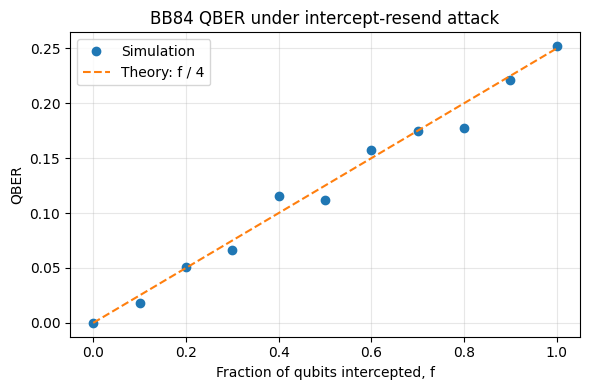

f = 0.0   QBER = 0.000
f = 0.1   QBER = 0.019
f = 0.2   QBER = 0.051
f = 0.3   QBER = 0.066
f = 0.4   QBER = 0.116
f = 0.5   QBER = 0.112
f = 0.6   QBER = 0.157
f = 0.7   QBER = 0.175
f = 0.8   QBER = 0.178
f = 0.9   QBER = 0.221
f = 1.0   QBER = 0.252


In [10]:
fractions = np.linspace(0, 1, 11)
qbers = [run_bb84(n_rounds=2000, eve_fraction=f, seed=100 + i)["qber"]
         for i, f in enumerate(fractions)]

plt.figure(figsize=(6, 4))
plt.plot(fractions, qbers, "o", label="Simulation")
plt.plot(fractions, 0.25 * fractions, "--", label="Theory: f / 4")
plt.xlabel("Fraction of qubits intercepted, f")
plt.ylabel("QBER")
plt.title("BB84 QBER under intercept-resend attack")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig1_bb84_qber_vs_eve.png", dpi=200)
plt.show()

for f, q in zip(fractions, qbers):
    print(f"f = {f:.1f}   QBER = {q:.3f}")

## 4. Discussion

The simulation reproduces the expected behaviour: zero QBER on an ideal channel, and a QBER that grows linearly with the interception fraction, reaching about 25% under full attack.

BB84 relies on each state being sent exactly once. A second copy would let an eavesdropper store one and measure it after the bases are announced, so multi-photon emissions are a known vulnerability that limits key rates over lossy channels.

The HM-QCT protocol (Mazzoncini et al., *Quantum* 9, 1862, 2025) relaxes this constraint. Alice encodes an *n*-bit string into a log₂*n*-qubit state and may send several copies. The information Bob needs to measure correctly (the matching) is sent under classical encryption, which is assumed to stay secure for longer than an eavesdropper's quantum memory remains coherent. Notebook 02 implements the Hidden Matching measurement that this protocol is built on.